# RetailIQ — Simple Python EDA

This notebook explores all four cleaned CSV files using simple Pandas charts and summaries.

**Before running:** Keep these files in the same folder as this notebook:
- `cleaned_customers.csv`
- `cleaned_products.csv`
- `cleaned_sales.csv`
- `cleaned_orders.csv`

Run each cell from top to bottom.


## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load all CSV files

In [3]:
customers = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_customers.csv")
products = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_products.csv")
sales = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_sales.csv")
orders = pd.read_csv("E:\CODING_ALL\Data Analytics\projrcts\RetailIQ\data\Cleaned csv\cleaned_orders.csv")

sales["order_date"] = pd.to_datetime(sales["order_date"], errors="coerce")

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Sales:", sales.shape)
print("Order items:", orders.shape)

Customers: (25000, 12)
Products: (1175, 10)
Sales: (138116, 26)
Order items: (397569, 14)


## 3. Quick look at all datasets

In [4]:
display(customers.head())
display(products.head())
display(sales.head())
display(orders.head())

,customer_id,customer_name,customer_age,age_range,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,50-60,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,60-70,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,40-50,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,30-40,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,50-60,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34


,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating,price_cost_difference
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.3,212.84
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.9,458.60
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.9,90.03
3,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,Smartphones,Sony,Amazon Supply,1120.49,564.86,4.8,555.63
4,PROD-000005,OnePlus Quality-focused background parallelism...,Electronics,Smartphones,OnePlus,Direct Import,1282.18,695.54,2.9,586.64


,order_id,order_date,order_status,sales_channel,customer_id,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,rating,customer_rating,review_sentiment,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,Completed,Mobile App,CUST-003102,Digital Wallet,Paid,USD,Standard,WH-003,3.0,3.0,On Time,NaN,NaN,4,3.5,Positive,Direct,Default_Campaign,NaN,94,44,12459.68,True,11
1,ORD-773460,2025-12-24,Completed,Website,CUST-003124,Debit Card,Pending,EUR,Economy,WH-005,10.0,10.0,On Time,NaN,NaN,4,3.6,Positive,Direct,Default_Campaign,NaN,201,171,13032.48,True,11
2,ORD-449374,2021-07-05,Completed,Mobile App,CUST-012496,Cash on Delivery,Paid,USD,Express,WH-015,3.0,3.0,On Time,NaN,NaN,4,4.3,Positive,YouTube,NaN,NaN,46,16,6159.44,True,6
3,ORD-567636,2023-01-21,Completed,Social Media,CUST-023928,Debit Card,Paid,USD,Express,WH-010,2.0,2.0,On Time,NaN,NaN,4,3.5,Positive,Email Marketing,NaN,NaN,54,10,5638.30,True,7
4,ORD-820028,2022-05-13,Completed,Social Media,CUST-012730,Digital Wallet,Paid,INR,Standard,WH-013,6.0,5.0,Delayed,NaN,NaN,3,3.0,Neutral,Direct,NaN,NaN,278,147,13240.10,True,8


,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit,expected_gross_sales,gross_sales_difference
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12,488.80,0.0
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92,861.39,0.0
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84,3019.20,0.0
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37,125.44,0.0
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53,18.93,0.0


## 4. Check missing values and duplicate rows

In [5]:
for name, df in [("Customers", customers), ("Products", products), ("Sales", sales), ("Order items", orders)]:
    print("\n", name)
    print("Missing values:", df.isna().sum().sum())
    print("Exact duplicate rows:", df.duplicated().sum())


 Customers
Missing values: 0
Exact duplicate rows: 0

 Products
Missing values: 0
Exact duplicate rows: 0

 Sales
Missing values: 549271
Exact duplicate rows: 0

 Order items
Missing values: 0
Exact duplicate rows: 0


## 5. Customer analysis

,customers
customer_segment,
Consumer,13638
Premium,6301
VIP,2542
Business,2519


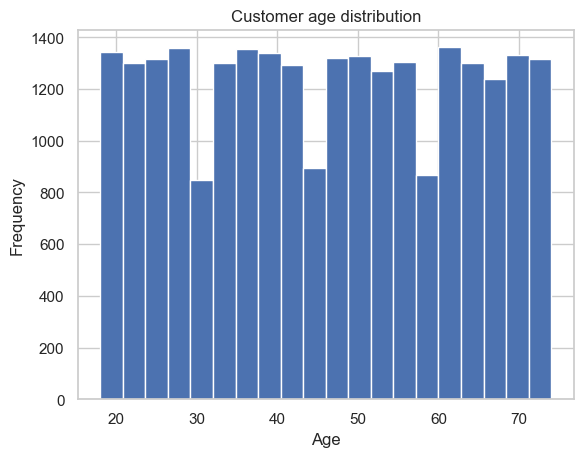

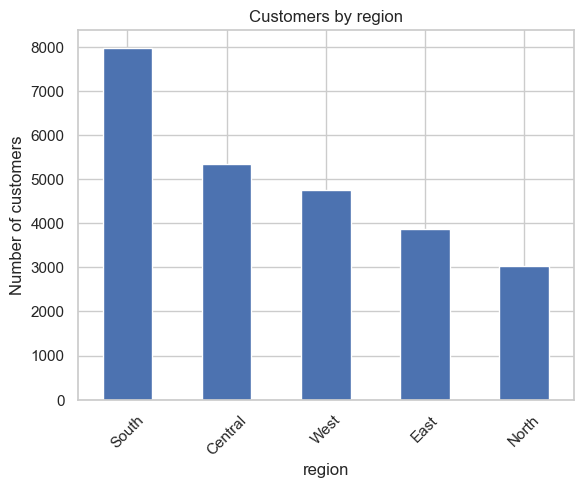

count    25000.000000
mean        42.159750
std         21.692648
min          5.010000
25%         23.297500
50%         41.980000
75%         61.130000
max         79.990000
Name: customer_acquisition_cost, dtype: float64

In [6]:
display(customers["customer_segment"].value_counts().to_frame("customers"))

customers["customer_age"].plot(kind="hist", bins=20, title="Customer age distribution")
plt.xlabel("Age")
plt.show()

customers["region"].value_counts().plot(kind="bar", title="Customers by region")
plt.ylabel("Number of customers")
plt.xticks(rotation=45)
plt.show()

display(customers["customer_acquisition_cost"].describe())

## 6. Product analysis

,number_of_products
product_category,
Sports & Outdoors,91
Books & Media,87
Health & Wellness,86
Beauty & Personal Care,83
Automotive,81
Office Supplies,80
Electronics,78
Home Appliances,78
Grocery,78


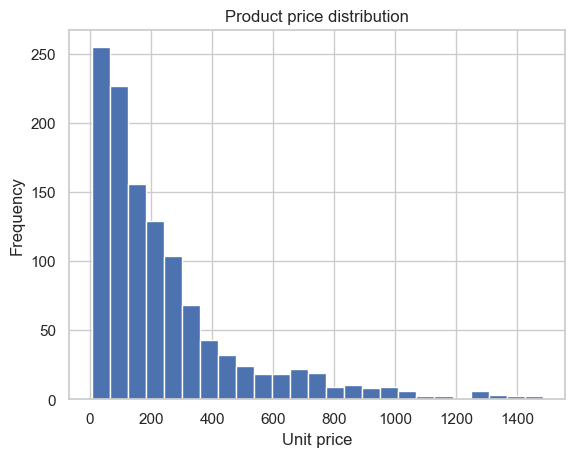

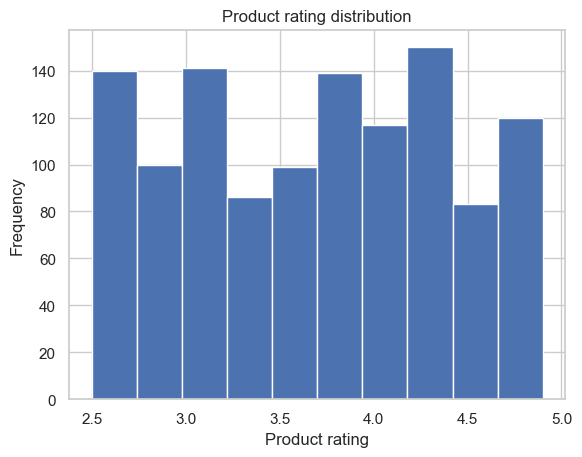

,unit_price,product_cost,catalogue_margin
count,1175.000000,1175.000000,1175.000000
mean,245.524400,126.536826,118.987574
std,251.267683,150.131833,108.289840
min,6.310000,1.970000,3.280000
25%,74.710000,29.565000,41.865000
50%,165.420000,74.540000,87.740000
75%,311.295000,153.045000,157.855000
max,1482.950000,993.630000,624.220000


In [7]:
display(products["product_category"].value_counts().to_frame("number_of_products"))

products["unit_price"].plot(kind="hist", bins=25, title="Product price distribution")
plt.xlabel("Unit price")
plt.show()

products["product_rating"].plot(kind="hist", bins=10, title="Product rating distribution")
plt.xlabel("Product rating")
plt.show()

products["catalogue_margin"] = products["unit_price"] - products["product_cost"]
display(products[["unit_price", "product_cost", "catalogue_margin"]].describe())

## 7. Order and sales analysis

,orders
order_status,
Completed,113559
Returned,9462
Cancelled,8398
Pending,6697


,delivery_days,estimated_delivery_days,customer_rating
count,113559.000000,113559.000000,113559.000000
mean,4.557772,4.298875,3.677015
std,2.810012,2.594080,0.483672
min,0.000000,0.000000,1.600000
25%,2.000000,2.000000,3.400000
50%,4.000000,4.000000,3.700000
75%,7.000000,6.000000,4.000000
max,14.000000,10.000000,5.000000


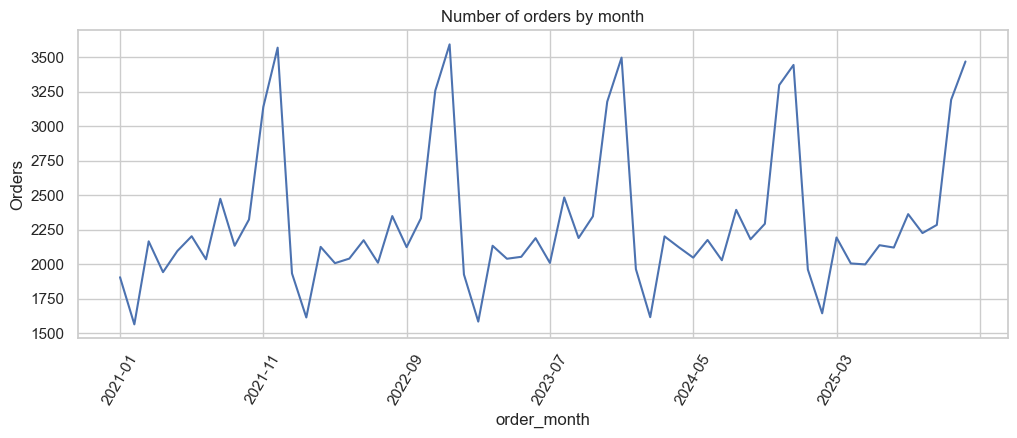

In [8]:
display(sales["order_status"].value_counts().to_frame("orders"))

display(sales[["delivery_days", "estimated_delivery_days", "customer_rating"]].describe())

sales["order_month"] = sales["order_date"].dt.to_period("M").astype(str)
monthly_orders = sales.groupby("order_month")["order_id"].nunique()
monthly_orders.plot(figsize=(12, 4), title="Number of orders by month")
plt.ylabel("Orders")
plt.xticks(rotation=60)
plt.show()

## 8. Sales channels and payment methods

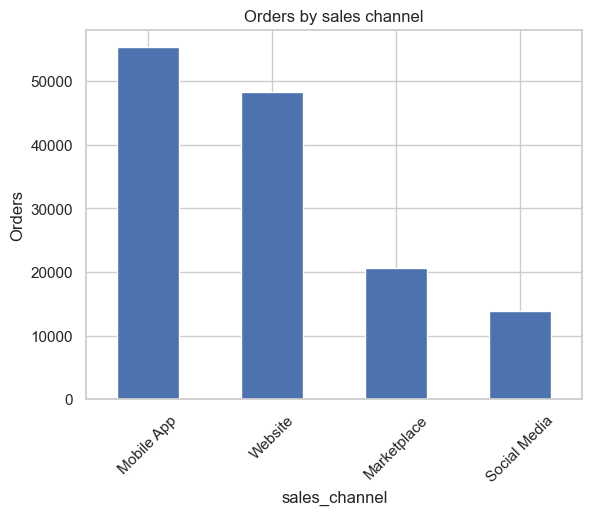

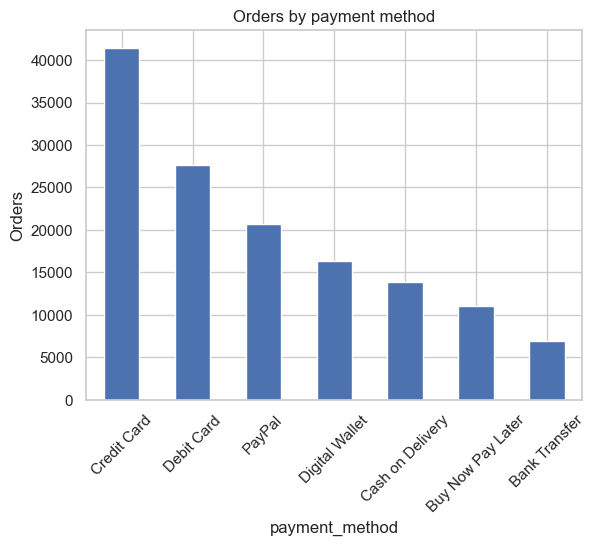

In [10]:
sales["sales_channel"].value_counts().plot(kind="bar", title="Orders by sales channel")
plt.ylabel("Orders")
plt.xticks(rotation=45)
plt.show()

sales["payment_method"].value_counts().plot(kind="bar", title="Orders by payment method")
plt.ylabel("Orders")
plt.xticks(rotation=45)
plt.show()

## 9. Overall sales, quantity and profit

In [11]:
money_cols = ["gross_sales", "discount_amount", "net_sales", "profit"]
display(orders[money_cols + ["quantity"]].describe().T)

print("Total units sold:", orders["quantity"].sum())
print("Total gross sales:", round(orders["gross_sales"].sum(), 2))
print("Total net sales:", round(orders["net_sales"].sum(), 2))
print("Total profit:", round(orders["profit"].sum(), 2))

,count,mean,std,min,25%,50%,75%,max
gross_sales,397569.0,519.013550,676.800478,6.31,122.00,280.19,643.56,7414.75
discount_amount,397569.0,89.667873,190.637796,0.00,5.94,26.34,86.03,3857.67
net_sales,397569.0,483.938328,615.430188,5.35,124.28,271.10,595.24,8897.70
profit,397569.0,208.009273,266.477677,-1260.28,53.73,121.66,259.66,4045.10
quantity,397569.0,2.118792,1.196276,1.00,1.00,2.00,3.00,5.00


Total units sold: 842366
Total gross sales: 206343698.09
Total net sales: 192398877.29
Total profit: 82698038.55


## 10. Discounts and profit

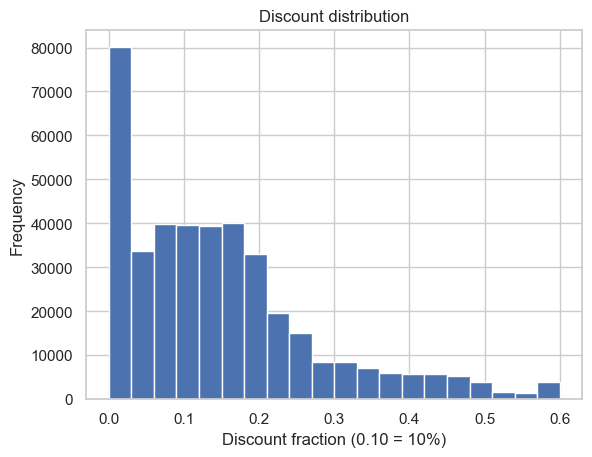

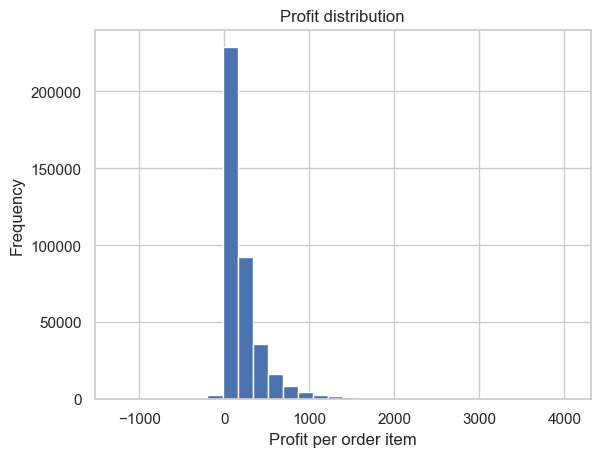

In [12]:
orders["discount_percentage"].plot(kind="hist", bins=20, title="Discount distribution")
plt.xlabel("Discount fraction (0.10 = 10%)")
plt.show()

orders["profit"].plot(kind="hist", bins=30, title="Profit distribution")
plt.xlabel("Profit per order item")
plt.show()

## 11. Category performance

,units_sold,net_sales,profit
product_category,,,
Electronics,55784,41148162.90,14103982.74
Jewelry,48859,25561333.78,10391635.32
Home Appliances,56281,24842478.64,10288878.45
Automotive,58046,16449898.28,6477194.28
Sports & Outdoors,64752,15726848.17,7230037.31
Home & Kitchen,49682,10971629.82,5203824.25
Baby & Kids,53945,9690605.60,4818148.07
Health & Wellness,62054,9228068.04,4263304.41
Office Supplies,57631,8884212.85,4585377.04


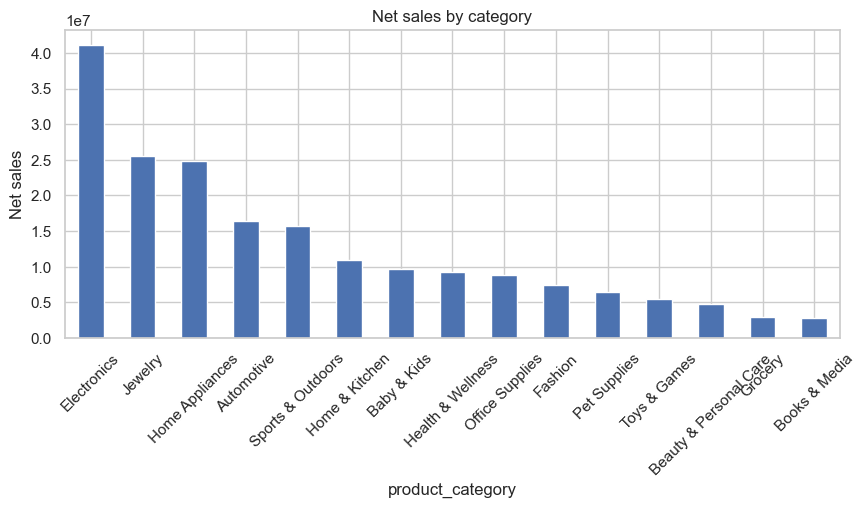

In [13]:
orders_products = orders.merge(
    products[["product_id", "product_name", "product_category"]],
    on="product_id", how="left"
)

category_sales = orders_products.groupby("product_category", dropna=False).agg(
    units_sold=("quantity", "sum"),
    net_sales=("net_sales", "sum"),
    profit=("profit", "sum")
).sort_values("net_sales", ascending=False)

display(category_sales.round(2))
category_sales["net_sales"].plot(kind="bar", figsize=(10, 4), title="Net sales by category")
plt.ylabel("Net sales")
plt.xticks(rotation=45)
plt.show()

## 12. Top 10 products by net sales

,units_sold,net_sales,profit
product_name,,,
Xiaomi Self-enabling exuding productivity Gaming Consoles,743,956726.44,315731.45
OnePlus Adaptive uniform success Gaming Consoles,767,946819.10,376805.41
Asus Configurable upward-trending matrix TVs,778,943941.34,300483.49
Asus Re-engineered content-based strategy Tablets,673,942549.52,286463.16
HP Versatile actuating budgetary management Smart Watches,717,909388.15,364187.95
OnePlus Switchable methodical neural-net TVs,716,900378.69,287872.13
OnePlus Streamlined modular infrastructure Smart Watches,754,885456.49,242450.76
LG Reverse-engineered even-keeled workforce Smartphones,668,883013.59,216683.84
Xiaomi Fundamental motivating task-force Gaming Consoles,738,857409.58,285324.29


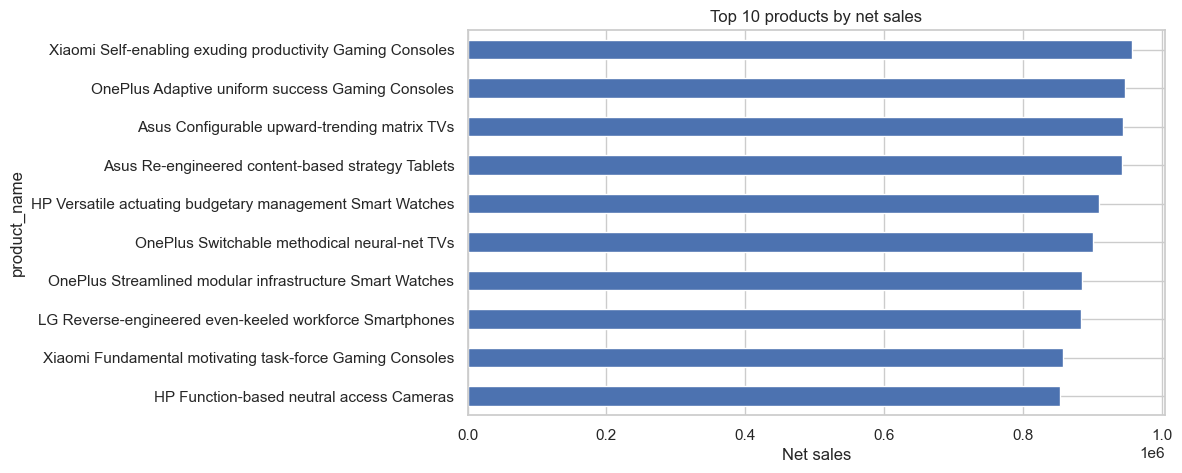

In [14]:
top_products = orders_products.groupby("product_name", dropna=False).agg(
    units_sold=("quantity", "sum"),
    net_sales=("net_sales", "sum"),
    profit=("profit", "sum")
).sort_values("net_sales", ascending=False).head(10)

display(top_products.round(2))
top_products["net_sales"].sort_values().plot(kind="barh", figsize=(9, 5), title="Top 10 products by net sales")
plt.xlabel("Net sales")
plt.show()

## 13. Customer spending

,orders,total_spending,total_profit
customer_id,,,
CUST-012869,15,36882.29,15041.82
CUST-011800,12,35447.76,16137.94
CUST-009330,13,32884.83,15061.97
CUST-018228,14,32564.96,11204.55
CUST-017251,15,31378.08,11381.84
CUST-017828,14,31330.87,13697.02
CUST-022868,11,30823.46,11018.59
CUST-009693,9,30719.47,11810.52
CUST-002969,16,30061.58,11703.80


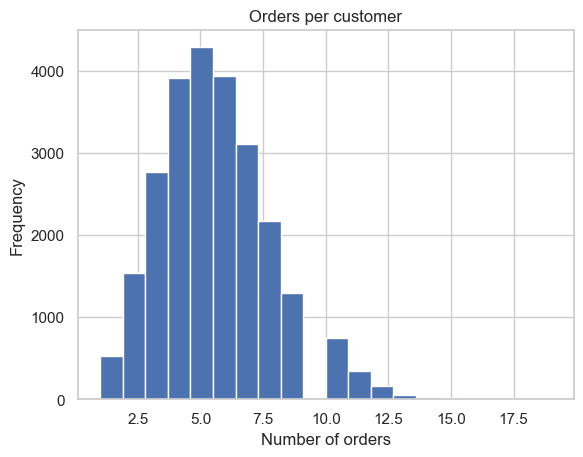

In [15]:
order_totals = orders.groupby("order_id", as_index=False).agg(
    order_net_sales=("net_sales", "sum"),
    order_profit=("profit", "sum")
)
customer_orders = sales[["order_id", "customer_id"]].merge(order_totals, on="order_id", how="left")
customer_spending = customer_orders.groupby("customer_id").agg(
    orders=("order_id", "nunique"),
    total_spending=("order_net_sales", "sum"),
    total_profit=("order_profit", "sum")
).sort_values("total_spending", ascending=False)

display(customer_spending.head(10).round(2))
customer_spending["orders"].plot(kind="hist", bins=20, title="Orders per customer")
plt.xlabel("Number of orders")
plt.show()

## 14. Delivery, returns and ratings

count    113559.000000
mean          0.258896
std           1.120265
min          -2.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           4.000000
Name: delivery_delay, dtype: float64


 delivery_status


,count
delivery_status,
On Time,86916
Cancelled,24557
Delayed,16886
Early,9757



 return_status


,count
return_status,
NaN,128654
Returned,9462



 review_sentiment


,count
review_sentiment,
Positive,78083
Neutral,34684
NaN,24557
Negative,792


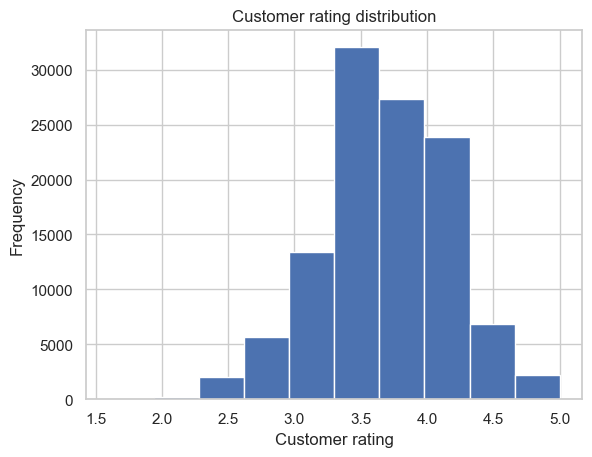

In [16]:
if "delivery_days" in sales.columns and "estimated_delivery_days" in sales.columns:
    sales["delivery_delay"] = sales["delivery_days"] - sales["estimated_delivery_days"]
    display(sales["delivery_delay"].describe())

for col in ["delivery_status", "return_status", "review_sentiment"]:
    if col in sales.columns:
        print("\n", col)
        display(sales[col].value_counts(dropna=False).to_frame("count"))

if "customer_rating" in sales.columns:
    sales["customer_rating"].plot(kind="hist", bins=10, title="Customer rating distribution")
    plt.xlabel("Customer rating")
    plt.show()

## 15. Final checks between CSV files

In [17]:
print("Order items without a matching order:", (~orders["order_id"].isin(sales["order_id"])).sum())
print("Order items without a matching product:", (~orders["product_id"].isin(products["product_id"])).sum())
print("Sales records without a matching customer:", (~sales["customer_id"].isin(customers["customer_id"])).sum())

print("Products never sold:", (~products["product_id"].isin(orders["product_id"])).sum())
print("Customers with no orders:", (~customers["customer_id"].isin(sales["customer_id"])).sum())

Order items without a matching order: 0
Order items without a matching product: 0
Sales records without a matching customer: 0
Products never sold: 0
Customers with no orders: 89
